# ===============================
# 02_StatisticalModels_ARIMA_Prophet.ipynb
# ===============================

Dataset shape: (844338, 32)
Train shape: (754, 32), Test shape: (27, 32)


19:40:05 - cmdstanpy - INFO - Chain [1] start processing
19:40:05 - cmdstanpy - INFO - Chain [1] done processing


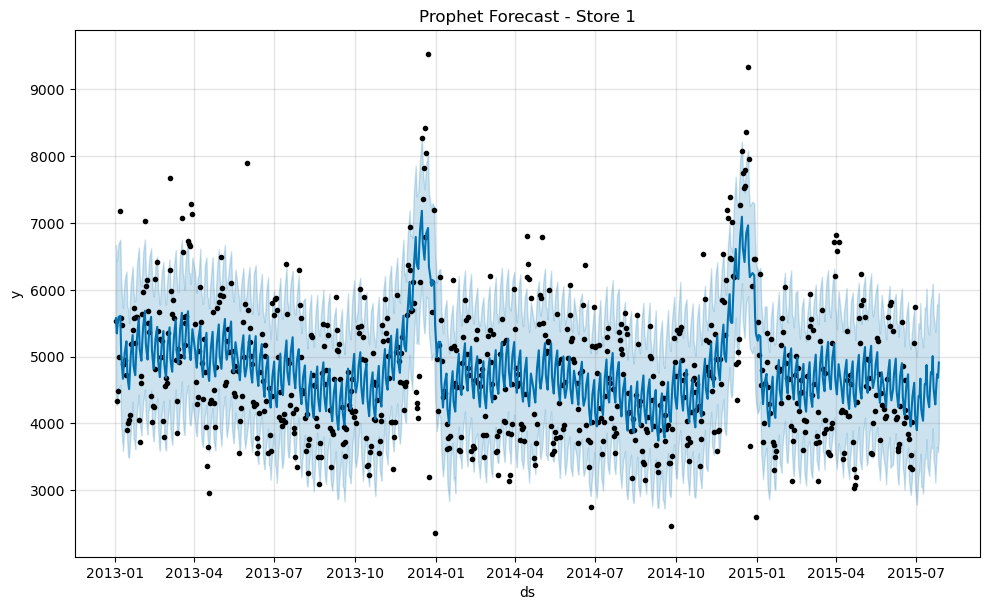

Prophet MAE: 590.83
Prophet RMSE: 780.73
RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            5     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.50649D+00    |proj g|=  5.84174D-01



 This problem is unconstrained.


At iterate    5    f=  8.03588D+00    |proj g|=  1.39057D-01

At iterate   10    f=  8.02689D+00    |proj g|=  1.00818D-02

At iterate   15    f=  8.02647D+00    |proj g|=  4.45922D-04

At iterate   20    f=  8.02645D+00    |proj g|=  4.32237D-03

At iterate   25    f=  8.02199D+00    |proj g|=  7.27510D-02

At iterate   30    f=  7.95555D+00    |proj g|=  3.01370D-01

At iterate   35    f=  7.91838D+00    |proj g|=  1.76288D-02

At iterate   40    f=  7.91830D+00    |proj g|=  1.19369D-05

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    5     40     50      1     0     0   1.194D-05   7.918D+00
  F =   7.918295352873

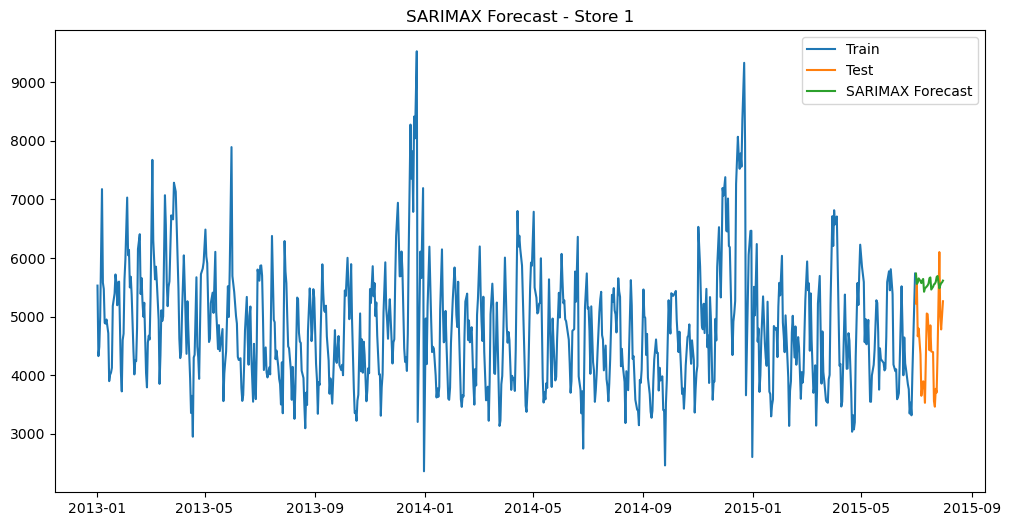

SARIMAX MAE: 1134.28
SARIMAX RMSE: 1285.03

===== Baseline Model Performance =====
Prophet - MAE: 590.83, RMSE: 780.73
SARIMAX - MAE: 1134.28, RMSE: 1285.03


In [ ]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Prophet
from prophet import Prophet

# ARIMA/SARIMAX
import statsmodels.api as sm

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 2. Load Feature-Engineered Data
df = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/feature_engineered_rossmann.csv', parse_dates=['Date'])
print(f"Dataset shape: {df.shape}")

# 3. Filter a Single Store for Simplicity First
store_id = 1  # You can later expand to multiple stores!
df_store = df[df['Store'] == store_id].copy()

# 4. Train-Test Split
train = df_store[df_store['Date'] < '2015-07-01']
test = df_store[df_store['Date'] >= '2015-07-01']

print(f"Train shape: {train.shape}, Test shape: {test.shape}")

# ===================================================
# PROPHET MODEL
# ===================================================

# 5. Prepare Data for Prophet
prophet_df = train[['Date', 'Sales']].rename(columns={'Date': 'ds', 'Sales': 'y'})

# 6. Train Prophet
model_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
model_prophet.fit(prophet_df)

# 7. Predict
future = model_prophet.make_future_dataframe(periods=len(test))
forecast = model_prophet.predict(future)

# 8. Plot Forecast
fig = model_prophet.plot(forecast)
plt.title(f"Prophet Forecast - Store {store_id}")
plt.show()

# 9. Evaluate Prophet
y_true = test['Sales'].values
y_pred_prophet = forecast[-len(test):]['yhat'].values

mae_prophet = mean_absolute_error(y_true, y_pred_prophet)
rmse_prophet = mean_squared_error(y_true, y_pred_prophet, squared=False)

print(f"Prophet MAE: {mae_prophet:.2f}")
print(f"Prophet RMSE: {rmse_prophet:.2f}")

# ===================================================
# ARIMA / SARIMAX MODEL
# ===================================================

# 10. Prepare Data for ARIMA
arima_df = train.set_index('Date')['Sales']

# 11. Fit SARIMAX
# (p,d,q) (P,D,Q,s) — manually chosen for now
model_sarimax = sm.tsa.statespace.SARIMAX(arima_df,
                                          order=(1,1,1),
                                          seasonal_order=(1,1,1,7),
                                          enforce_stationarity=False,
                                          enforce_invertibility=False)
results_sarimax = model_sarimax.fit()

# 12. Forecast
pred_sarimax = results_sarimax.get_forecast(steps=len(test))
y_pred_sarimax = pred_sarimax.predicted_mean

# 13. Plot SARIMAX Forecast
plt.figure(figsize=(12,6))
plt.plot(train['Date'], train['Sales'], label='Train')
plt.plot(test['Date'], test['Sales'], label='Test')
plt.plot(test['Date'], y_pred_sarimax, label='SARIMAX Forecast')
plt.legend()
plt.title(f"SARIMAX Forecast - Store {store_id}")
plt.show()

# 14. Evaluate SARIMAX
mae_sarimax = mean_absolute_error(y_true, y_pred_sarimax)
rmse_sarimax = mean_squared_error(y_true, y_pred_sarimax, squared=False)

print(f"SARIMAX MAE: {mae_sarimax:.2f}")
print(f"SARIMAX RMSE: {rmse_sarimax:.2f}")

# ===================================================
# Summary of Baseline Models
# ===================================================

print("\n===== Baseline Model Performance =====")
print(f"Prophet - MAE: {mae_prophet:.2f}, RMSE: {rmse_prophet:.2f}")
print(f"SARIMAX - MAE: {mae_sarimax:.2f}, RMSE: {rmse_sarimax:.2f}")
